# Avaliação no split de teste

Avalia o checkpoint treinado no split de teste (nunca visto em treino/validação): top-1/top-2, macro-F1, acurácia por grupo de Denver, matriz de confusão e métricas por classe. Salva as probabilidades softmax do teste (`test_probs.npy`), usadas depois na Fase 5. O pré-processamento (letterbox ou esticado) é lido do próprio checkpoint, então serve para qualquer run.

No fim, compara com uma run de referência sobre os mesmos recortes de teste (teste de McNemar). Para contexto, o paper de referência reporta 94.04% de acurácia de validação na rota (b) YOLOv8 + ResNet-50 -- não comparável diretamente: o paper treina no Dataset B (Q-band, isolados e balanceados), usa outro split e filtra metáfases com sobreposição.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path("../../..").resolve()
sys.path.insert(0, str(REPO_ROOT / "src" / "classification"))
sys.path.insert(0, str(REPO_ROOT / "src" / "preprocessing"))

from evaluate import evaluate

CHECKPOINT = Path("../runs/resnet50-paper/best.pt")  # mesmo RUN_NAME de 02_train.ipynb
BASELINE = Path("../runs/resnet50-30epochs")  # run de referência para a comparação no fim

metrics = evaluate(CHECKPOINT)

Top-1: 0.9848  Top-2: 0.9943  Macro-F1: 0.9838
Acurácia por grupo de Denver:
  A: 0.9976
  B: 0.9903
  C: 0.9911
  D: 0.9886
  E: 0.9889
  F: 0.9830
  G: 0.9863
  X: 0.9675
  Y: 0.9492
Probabilidades salvas em: ../runs/resnet50-paper/test_probs.npy


## Matriz de confusão

Normalizada por linha (cada linha soma 100% dos cromossomos daquela classe real), com a diagonal removida para os erros ficarem visíveis -- o recall de cada classe aparece no rótulo do eixo. As linhas cinzas separam os grupos de Denver. Os erros esperados são entre classes de tamanho e forma parecidos: dentro do mesmo grupo (C6-C12, D13-D15, G21/G22), X com o grupo C e Y com o grupo G.

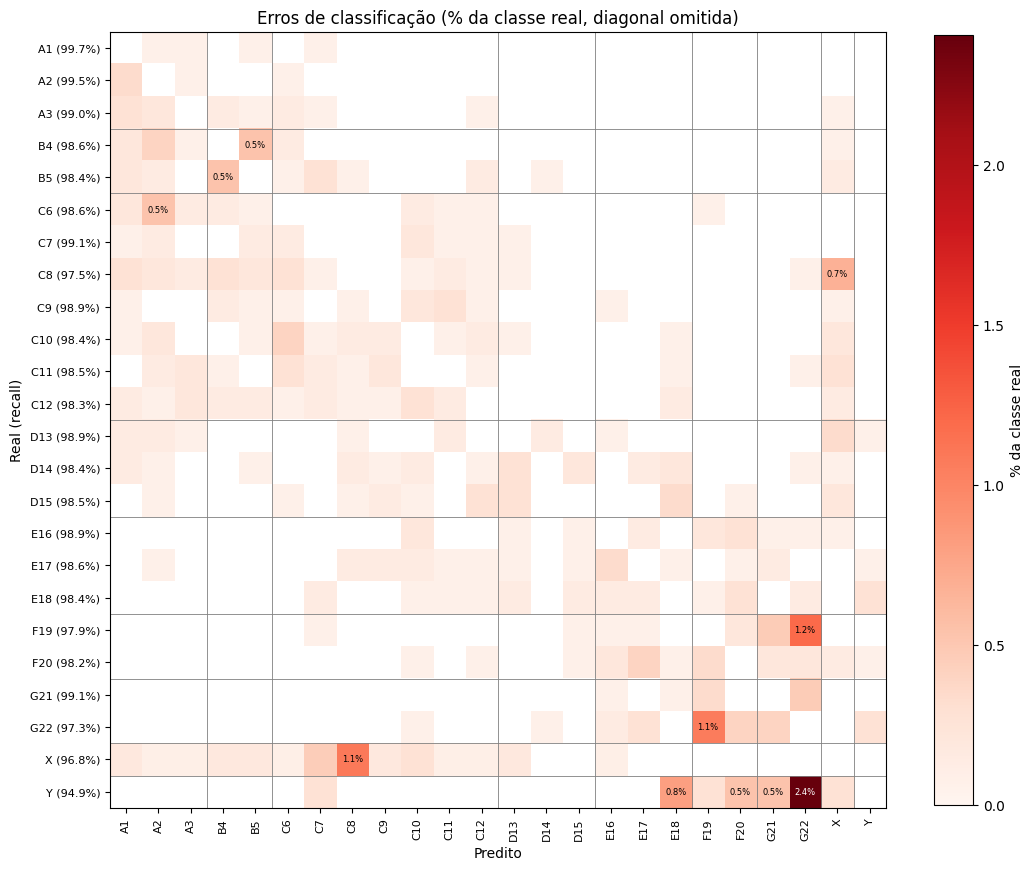

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from voc_to_yolo import DENVER_CLASSES

cm = np.array(metrics["confusion_matrix"], dtype=float)
cm_norm = cm / cm.sum(axis=1, keepdims=True)
recall = np.diag(cm_norm)
errors = cm_norm.copy()
np.fill_diagonal(errors, np.nan)
errors[errors == 0] = np.nan  # sem nenhum erro -> branco

fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(errors * 100, cmap="Reds", vmin=0)
n = len(DENVER_CLASSES)
ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(DENVER_CLASSES, rotation=90, fontsize=8)
ax.set_yticklabels([f"{c} ({r:.1%})" for c, r in zip(DENVER_CLASSES, recall, strict=True)], fontsize=8)
vmax = np.nanmax(errors)
for i in range(n):
    for j in range(n):
        if errors[i, j] >= 0.005:
            color = "white" if errors[i, j] > 0.6 * vmax else "black"
            ax.text(j, i, f"{errors[i, j]:.1%}", ha="center", va="center", fontsize=6, color=color)

groups = [c[0] for c in DENVER_CLASSES]
for k in range(1, n):
    if groups[k] != groups[k - 1]:
        ax.axhline(k - 0.5, color="gray", linewidth=0.6)
        ax.axvline(k - 0.5, color="gray", linewidth=0.6)

ax.set_xlabel("Predito")
ax.set_ylabel("Real (recall)")
ax.set_title("Erros de classificação (% da classe real, diagonal omitida)")
fig.colorbar(im, label="% da classe real", shrink=0.8)
plt.tight_layout()
plt.show()

## Métricas por classe

Precisão, recall e F1 de cada uma das 24 classes, ordenadas pelo F1 -- as piores no topo.

In [3]:
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support

labels = np.load(CHECKPOINT.parent / "test_labels.npy")
preds = np.load(CHECKPOINT.parent / "test_probs.npy").argmax(axis=1)

precision, rec, f1, support = precision_recall_fscore_support(
    labels, preds, labels=range(n), zero_division=0
)
per_class = pd.DataFrame(
    {"precisão": precision, "recall": rec, "F1": f1, "n": support}, index=DENVER_CLASSES
)
per_class.sort_values("F1").round(4)

,precisão,recall,F1,n
Y,0.9699,0.9492,0.9595,374
X,0.9666,0.9675,0.9671,1108
G22,0.9713,0.9733,0.9723,1497
F19,0.9787,0.9787,0.9787,1499
C8,0.9838,0.9753,0.9796,1498
C10,0.9820,0.9840,0.9830,1497
F20,0.9859,0.9820,0.9839,1498
B5,0.9846,0.9840,0.9843,1499
C6,0.9827,0.9860,0.9843,1498
C12,0.9872,0.9833,0.9853,1496


## Comparação com a run de referência

As duas runs são avaliadas sobre exatamente os mesmos recortes de teste, então dá para comparar recorte a recorte. O teste de McNemar (exato) olha só os casos em que uma run acerta e a outra erra, e diz se esse desequilíbrio pode ser explicado por acaso -- p < 0.05 indica diferença real. Com uma única run por configuração (sem repetir seeds), diferenças pequenas e com p alto devem ser tratadas como ruído.

Atenção: aqui a acurácia é da **classe exata** (A1 previsto como A2 conta como erro). A "acurácia por grupo de Denver" impressa pelo `evaluate` no início é mais tolerante -- conta como acerto qualquer predição dentro do grupo certo. Para X e Y as duas coincidem.

In [4]:
from scipy.stats import binomtest

baseline_labels = np.load(BASELINE / "test_labels.npy")
assert np.array_equal(baseline_labels, labels), "as runs não usam o mesmo split de teste"
baseline_preds = np.load(BASELINE / "test_probs.npy").argmax(axis=1)

class_group = np.array([c[0] for c in DENVER_CLASSES])
subsets = {"geral": np.ones_like(labels, dtype=bool)}
subsets |= {g: class_group[labels] == g for g in "ABCDEFG"}
subsets |= {c: labels == DENVER_CLASSES.index(c) for c in ("X", "Y")}

rows = []
for name, mask in subsets.items():
    base_ok, new_ok = baseline_preds[mask] == labels[mask], preds[mask] == labels[mask]
    only_base, only_new = int((base_ok & ~new_ok).sum()), int((~base_ok & new_ok).sum())
    discordant = only_base + only_new
    rows.append({
        "n": int(mask.sum()),
        f"acc. exata {BASELINE.name}": base_ok.mean(),
        f"acc. exata {CHECKPOINT.parent.name}": new_ok.mean(),
        "só referência acerta": only_base,
        "só nova acerta": only_new,
        "p (McNemar)": binomtest(only_new, discordant, 0.5).pvalue if discordant else 1.0,
    })
pd.DataFrame(rows, index=list(subsets)).round(4)

,n,acc. exata resnet50-30epochs,acc. exata resnet50-paper,só referência acerta,só nova acerta,p (McNemar)
geral,34434,0.9822,0.9848,229,319,0.0001
A,4493,0.9927,0.9942,19,26,0.3713
B,2996,0.9790,0.9850,22,40,0.0300
C,10483,0.9804,0.9848,62,108,0.0005
D,4493,0.9855,0.9858,33,34,1.0000
E,4494,0.9844,0.9862,28,36,0.3817
F,2997,0.9783,0.9803,19,25,0.4514
G,2996,0.9750,0.9820,17,38,0.0065
X,1108,0.9765,0.9675,16,6,0.0525
Y,374,0.9679,0.9492,13,6,0.1671
